Chart saved successfully as 'top_chess_rating_gainers_2025.png'!


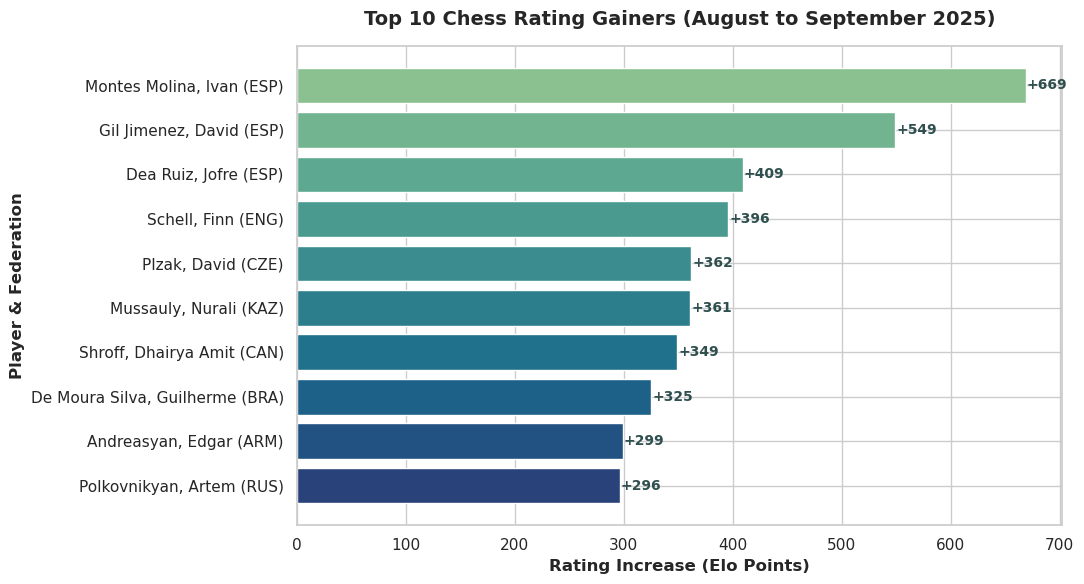

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load August and September 2025 FIDE ratings directly from TidyTuesday GitHub
url_aug = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-23/fide_ratings_august.csv"
url_sep = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-23/fide_ratings_september.csv"

print("Downloading dataset...")
df_aug = pd.read_csv(url_aug)
df_sep = pd.read_csv(url_sep)

# 2. Merge datasets on player ID to track changes
merged = pd.merge(
    df_sep[["id", "name", "fed", "title", "rating"]],
    df_aug[["id", "rating"]],
    on="id",
    suffixes=("_sep", "_aug"),
)

# 3. Calculate rating difference and find top gainers
merged["rating_diff"] = merged["rating_sep"] - merged["rating_aug"]
top_gainers = merged.sort_values(by="rating_diff", ascending=False).head(10)

# 4. Set up the visualization style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

# Create horizontal bar chart
palette = sns.color_palette("crest", len(top_gainers))
bars = plt.barh(
    top_gainers["name"] + " (" + top_gainers["fed"] + ")",
    top_gainers["rating_diff"],
    color=palette,
)

# Styling labels and title
plt.xlabel("Rating Increase (Elo Points)", fontsize=12, fontweight="bold")
plt.ylabel("Player & Federation", fontsize=12, fontweight="bold")
plt.title(
    "Top 10 Chess Rating Gainers (August to September 2025)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.gca().invert_yaxis()  # Put the highest gainer at the very top

# Add exact point annotations to each bar
for bar in bars:
  width = bar.get_width()
  plt.text(
      width + 1,
      bar.get_y() + bar.get_height() / 2,
      f"+{int(width)}",
      va="center",
      ha="left",
      fontsize=10,
      fontweight="bold",
      color="darkslategray",
  )

# Save and display
plt.tight_layout()
plt.savefig("top_chess_rating_gainers_2025.png", dpi=300)
print("Chart saved successfully as 'top_chess_rating_gainers_2025.png'!")
plt.show()